In [11]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU for now")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [12]:
!git clone https://github.com/IDKiro/DehazeFormer.git
%cd DehazeFormer
!ls

Cloning into 'DehazeFormer'...
remote: Enumerating objects: 94, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 94 (delta 17), reused 11 (delta 11), pack-reused 70 (from 2)
Receiving objects: 100% (94/94), 768.88 KiB | 3.09 MiB/s, done.
Resolving deltas: 100% (43/43), done.
/content/DehazeFormer
configs   figs	   models     requirements.txt	test.py   utils
datasets  LICENSE  README.md  run.sh		train.py


In [13]:
%cd /content/DehazeFormer

!pip install timm pytorch-msssim

/content/DehazeFormer


In [14]:
import os
import shutil

checkpoint = "/content/dehazeformer-t.pth"
destination = "/content/DehazeFormer/dehazeformer-t.pth"

if os.path.exists(checkpoint):
    shutil.move(checkpoint, destination)
    print("SUCCESS: Checkpoint is ready!")
    print("File size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")
elif os.path.exists(destination):
    print("SUCCESS: Checkpoint is already in the project folder!")
    print("File size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")
else:
    print("Checkpoint not found. Files in /content:")
    print(os.listdir("/content"))

Checkpoint not found. Files in /content:
['.config', 'drive', 'DehazeFormer', 'sample_data']


In [15]:
%cd /content/DehazeFormer

!sed -n '1,240p' test.py

/content/DehazeFormer
import os
import argparse
import torch
import torch.nn as nn
import torch.nn.functional as F
from pytorch_msssim import ssim
from torch.utils.data import DataLoader
from collections import OrderedDict

from utils import AverageMeter, write_img, chw_to_hwc
from datasets.loader import PairLoader
from models import *


parser = argparse.ArgumentParser()
parser.add_argument('--model', default='dehazeformer-s', type=str, help='model name')
parser.add_argument('--num_workers', default=16, type=int, help='number of workers')
parser.add_argument('--data_dir', default='./data/', type=str, help='path to dataset')
parser.add_argument('--save_dir', default='./saved_models/', type=str, help='path to models saving')
parser.add_argument('--result_dir', default='./results/', type=str, help='path to results saving')
parser.add_argument('--dataset', default='RESIDE-IN', type=str, help='dataset name')
parser.add_argument('--exp', default='indoor', type=str, help='experiment setting'

In [25]:
import torch

path = "/content/DehazeFormer/dehazeformer-t.pth"
checkpoint = torch.load(path, map_location="cpu", weights_only=False)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:20])
    if "state_dict" in checkpoint:
        print("State dict keys:", list(checkpoint["state_dict"].keys())[:5])
    else:
        print("This checkpoint does not contain a 'state_dict' key.")

Checkpoint type: <class 'dict'>
Checkpoint keys: ['state_dict']
State dict keys: ['module.patch_embed.proj.weight', 'module.patch_embed.proj.bias', 'module.layer1.blocks.0.attn.conv.weight', 'module.layer1.blocks.0.attn.conv.bias', 'module.layer1.blocks.0.attn.V.weight']


In [24]:
%cd /content/DehazeFormer

import torch
from collections import OrderedDict
from models import dehazeformer_t

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the architecture that matches dehazeformer-t.pth
model = dehazeformer_t().to(device)

# Load pretrained weights
checkpoint = torch.load(
    "/content/DehazeFormer/dehazeformer-t.pth",
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["state_dict"]

# Remove the DataParallel "module." prefix
new_state_dict = OrderedDict(
    (key[7:] if key.startswith("module.") else key, value)
    for key, value in state_dict.items()
)

model.load_state_dict(new_state_dict)
model.eval()

print("Model loaded successfully!")
print("Device:", device)

/content/DehazeFormer
Model loaded successfully!
Device: cuda


In [23]:
from google.colab import files

uploaded = files.upload()

Saving dehazeformer-t.pth to dehazeformer-t.pth


In [26]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:

import os

base = "/content/drive/MyDrive"

print("Folders and files in Google Drive:")
for item in os.listdir(base):
    print(item)


Folders and files in Google Drive:
Untitled document (1).gdoc
Untitled document.gdoc
Resume.gdoc
34dd-9d6a-4744-9216-950c7a0154fc (1).mp3
Colab Notebooks
Dehazing_Project


In [28]:

import os

dataset_path = "/content/drive/MyDrive/Dehazing_Project"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for name in files[:5]:
        print(f"{indent}  {name}")
    if level >= 3:
        dirs[:] = []


Dehazing_Project/
  rise/
    metadata_indoor.csv
    outdoor/
      hazy/
        0001_0.8_0.2.jpg
        0002_0.8_0.08.jpg
        0003_0.8_0.2.jpg
        0004_0.9_0.12.jpg
        0006_0.85_0.08.jpg
      clear/
        0001.png
        0002.png
        0003.png
        0004.png
        0006.png
    indoor/
      hazy/
        1400_1.png
        1400_10.png
        1400_2.png
        1400_3.png
        1400_4.png
      clear/
        1400.png
        1401.png
        1402.png
        1403.png
        1404.png


In [29]:

import os

dataset_path = "/content/drive/MyDrive/Dehazing_Project/rise"

for scene in ["indoor", "outdoor"]:
    print(f"\n--- {scene.upper()} ---")

    for category in ["hazy", "clear"]:
        folder = os.path.join(dataset_path, scene, category)

        if os.path.isdir(folder):
            images = [
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]
            print(f"{category}: {len(images)} images")
            print("Examples:", images[:5])
        else:
            print(f"Missing folder: {folder}")



--- INDOOR ---
hazy: 500 images
Examples: ['1400_1.png', '1400_10.png', '1400_2.png', '1400_3.png', '1400_4.png']
clear: 50 images
Examples: ['1400.png', '1401.png', '1402.png', '1403.png', '1404.png']

--- OUTDOOR ---
hazy: 500 images
Examples: ['0001_0.8_0.2.jpg', '0002_0.8_0.08.jpg', '0003_0.8_0.2.jpg', '0004_0.9_0.12.jpg', '0006_0.85_0.08.jpg']
clear: 492 images
Examples: ['0001.png', '0002.png', '0003.png', '0004.png', '0006.png']


In [30]:

import os

dataset_path = "/content/drive/MyDrive/Dehazing_Project/rise"
image_exts = (".jpg", ".jpeg", ".png", ".bmp")

for root, dirs, files in os.walk(dataset_path):
    images = [f for f in files if f.lower().endswith(image_exts)]

    if images:
        print(f"\nFolder: {root}")
        print(f"Image count: {len(images)}")
        print("First 8 images:", images[:8])



Folder: /content/drive/MyDrive/Dehazing_Project/rise/outdoor/hazy
Image count: 500
First 8 images: ['0001_0.8_0.2.jpg', '0002_0.8_0.08.jpg', '0003_0.8_0.2.jpg', '0004_0.9_0.12.jpg', '0006_0.85_0.08.jpg', '0007_0.9_0.16.jpg', '0009_0.8_0.16.jpg', '0010_0.95_0.16.jpg']

Folder: /content/drive/MyDrive/Dehazing_Project/rise/outdoor/clear
Image count: 492
First 8 images: ['0001.png', '0002.png', '0003.png', '0004.png', '0006.png', '0007.png', '0009.png', '0010.png']

Folder: /content/drive/MyDrive/Dehazing_Project/rise/indoor/hazy
Image count: 500
First 8 images: ['1400_1.png', '1400_10.png', '1400_2.png', '1400_3.png', '1400_4.png', '1400_5.png', '1400_6.png', '1400_7.png']

Folder: /content/drive/MyDrive/Dehazing_Project/rise/indoor/clear
Image count: 50
First 8 images: ['1400.png', '1401.png', '1402.png', '1403.png', '1404.png', '1405.png', '1406.png', '1407.png']


In [31]:

import os
import pandas as pd

csv_path = "/content/drive/MyDrive/Dehazing_Project/rise/metadata_indoor.csv"

df = pd.read_csv(csv_path)

print("Metadata shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))


Metadata shape: (50, 3)

Column names:
['image_id', 'clear_image_path', 'hazy_image_paths']

First 10 rows:


,image_id,clear_image_path,hazy_image_paths
0,1400,clear/1400.png,"['hazy/1400_1.png', 'hazy/1400_2.png', 'hazy/1..."
1,1401,clear/1401.png,"['hazy/1401_1.png', 'hazy/1401_2.png', 'hazy/1..."
2,1402,clear/1402.png,"['hazy/1402_1.png', 'hazy/1402_2.png', 'hazy/1..."
3,1403,clear/1403.png,"['hazy/1403_1.png', 'hazy/1403_2.png', 'hazy/1..."
4,1404,clear/1404.png,"['hazy/1404_1.png', 'hazy/1404_2.png', 'hazy/1..."
5,1405,clear/1405.png,"['hazy/1405_1.png', 'hazy/1405_2.png', 'hazy/1..."
6,1406,clear/1406.png,"['hazy/1406_1.png', 'hazy/1406_2.png', 'hazy/1..."
7,1407,clear/1407.png,"['hazy/1407_1.png', 'hazy/1407_2.png', 'hazy/1..."
8,1408,clear/1408.png,"['hazy/1408_1.png', 'hazy/1408_2.png', 'hazy/1..."
9,1409,clear/1409.png,"['hazy/1409_1.png', 'hazy/1409_2.png', 'hazy/1..."


In [32]:

import os

base = "/content/drive/MyDrive/Dehazing_Project"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    if level <= 3:
        print(root, "| folders:", dirs, "| image files:",
              sum(f.lower().endswith((".jpg", ".jpeg", ".png"))
                  for f in files))


/content/drive/MyDrive/Dehazing_Project | folders: ['rise'] | image files: 0
/content/drive/MyDrive/Dehazing_Project/rise | folders: ['outdoor', 'indoor'] | image files: 0
/content/drive/MyDrive/Dehazing_Project/rise/outdoor | folders: ['hazy', 'clear'] | image files: 0
/content/drive/MyDrive/Dehazing_Project/rise/outdoor/hazy | folders: [] | image files: 500
/content/drive/MyDrive/Dehazing_Project/rise/outdoor/clear | folders: [] | image files: 492
/content/drive/MyDrive/Dehazing_Project/rise/indoor | folders: ['hazy', 'clear'] | image files: 0
/content/drive/MyDrive/Dehazing_Project/rise/indoor/hazy | folders: [] | image files: 500
/content/drive/MyDrive/Dehazing_Project/rise/indoor/clear | folders: [] | image files: 50


In [33]:

import os
import ast
import pandas as pd

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"
csv_path = os.path.join(base, "..", "metadata_indoor.csv")

df = pd.read_csv(csv_path)

valid_pairs = []
missing_hazy = 0
missing_clear = 0

for _, row in df.iterrows():
    clear_path = os.path.join(base, row["clear_image_path"])

    if not os.path.isfile(clear_path):
        missing_clear += 1
        continue

    hazy_paths = ast.literal_eval(row["hazy_image_paths"])

    for hazy_rel_path in hazy_paths:
        hazy_path = os.path.join(base, hazy_rel_path)

        if os.path.isfile(hazy_path):
            valid_pairs.append((hazy_path, clear_path))
        else:
            missing_hazy += 1

print("Metadata rows:", len(df))
print("Valid hazy-clear pairs:", len(valid_pairs))
print("Missing clear references:", missing_clear)
print("Missing hazy images listed in metadata:", missing_hazy)

print("\nExample valid pairs:")
for hazy, clear in valid_pairs[:5]:
    print("Hazy:", os.path.basename(hazy))
    print("Clear:", os.path.basename(clear))
    print()


Metadata rows: 50
Valid hazy-clear pairs: 500
Missing clear references: 0
Missing hazy images listed in metadata: 0

Example valid pairs:
Hazy: 1400_1.png
Clear: 1400.png

Hazy: 1400_2.png
Clear: 1400.png

Hazy: 1400_3.png
Clear: 1400.png

Hazy: 1400_4.png
Clear: 1400.png

Hazy: 1400_5.png
Clear: 1400.png



In [34]:

%cd /content
!git clone https://github.com/IDKiro/DehazeFormer.git



/content
fatal: destination path 'DehazeFormer' already exists and is not an empty directory.


In [17]:

!pip install timm pytorch-msssim scikit-image


In [19]:

from google.colab import files

uploaded = files.upload()


Saving dehazeformer-t.pth to dehazeformer-t.pth


In [38]:

import os

for folder in ["/content", "/content/drive/MyDrive/Dehazing_Project"]:
    print(f"\nSearching: {folder}")
    for root, dirs, files in os.walk(folder):
        if "dehazeformer-t.pth" in files:
            print("FOUND:", os.path.join(root, "dehazeformer-t.pth"))



Searching: /content
FOUND: /content/DehazeFormer/dehazeformer-t.pth

Searching: /content/drive/MyDrive/Dehazing_Project


In [39]:

import shutil
import os

source = "/content/dehazeformer-t.pth"
destination = "/content/DehazeFormer/dehazeformer-t.pth"

shutil.move(source, destination)

print("Checkpoint ready:", os.path.exists(destination))


FileNotFoundError: [Errno 2] No such file or directory: '/content/dehazeformer-t.pth'

In [40]:

%cd /content/DehazeFormer

import torch
from collections import OrderedDict
from models import dehazeformer_t

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = dehazeformer_t().to(device)

checkpoint = torch.load(
    "dehazeformer-t.pth",
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["state_dict"]
state_dict = OrderedDict(
    (k[7:] if k.startswith("module.") else k, v)
    for k, v in state_dict.items()
)

model.load_state_dict(state_dict)
model.eval()

print("Model loaded successfully!")
print("Device:", device)


/content/DehazeFormer
Model loaded successfully!
Device: cuda


In [41]:

import os
import ast
import time
import numpy as np
import pandas as pd
import torch
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"
csv_path = os.path.join(base, "..", "metadata_indoor.csv")
df = pd.read_csv(csv_path)

valid_pairs = []
for _, row in df.iterrows():
    clear_path = os.path.join(base, row["clear_image_path"])
    if not os.path.isfile(clear_path):
        continue
    for rel_path in ast.literal_eval(row["hazy_image_paths"]):
        hazy_path = os.path.join(base, rel_path)
        if os.path.isfile(hazy_path):
            valid_pairs.append((hazy_path, clear_path))

print("Valid pairs:", len(valid_pairs))

def load_image(path):
    img = Image.open(path).convert("RGB")
    arr = np.asarray(img, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)
    return img, (tensor * 2.0 - 1.0).to(device)

results = []
os.makedirs("/content/dehazed_results", exist_ok=True)

for i, (hazy_path, clear_path) in enumerate(valid_pairs):
    hazy_img, input_tensor = load_image(hazy_path)
    clear_img = Image.open(clear_path).convert("RGB")

    if clear_img.size != hazy_img.size:
        clear_img = clear_img.resize(hazy_img.size, Image.Resampling.BICUBIC)

    clear_array = np.asarray(clear_img, dtype=np.float32) / 255.0
    hazy_array = np.asarray(hazy_img, dtype=np.float32) / 255.0

    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.no_grad():
        output = model(input_tensor).clamp(-1, 1)

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    output_array = (
        output.squeeze(0).permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5
    ).clip(0, 1)

    results.append({
        "hazy_image": os.path.basename(hazy_path),
        "clear_image": os.path.basename(clear_path),
        "PSNR_before": peak_signal_noise_ratio(
            clear_array, hazy_array, data_range=1.0
        ),
        "PSNR_after": peak_signal_noise_ratio(
            clear_array, output_array, data_range=1.0
        ),
        "SSIM_before": structural_similarity(
            clear_array, hazy_array, channel_axis=2, data_range=1.0
        ),
        "SSIM_after": structural_similarity(
            clear_array, output_array, channel_axis=2, data_range=1.0
        ),
        "inference_seconds": elapsed
    })

    if i == 0:
        Image.fromarray(
            (output_array * 255).astype(np.uint8)
        ).save("/content/dehazed_results/example_dehazed.png")

    if (i + 1) % 10 == 0:
        print(f"Processed {i + 1}/{len(valid_pairs)}")

results_df = pd.DataFrame(results)
results_df.to_csv("/content/dehazing_evaluation.csv", index=False)

print("\n===== EVALUATION SUMMARY =====")
print("Pairs evaluated:", len(results_df))
print(f"PSNR before: {results_df['PSNR_before'].mean():.3f} dB")
print(f"PSNR after:  {results_df['PSNR_after'].mean():.3f} dB")
print(f"SSIM before: {results_df['SSIM_before'].mean():.4f}")
print(f"SSIM after:  {results_df['SSIM_after'].mean():.4f}")
print(f"Average inference time: {results_df['inference_seconds'].mean():.4f} sec/image")
print("\nCSV saved to /content/dehazing_evaluation.csv")


Valid pairs: 500
Processed 10/500
Processed 20/500
Processed 30/500
Processed 40/500
Processed 50/500
Processed 60/500
Processed 70/500
Processed 80/500
Processed 90/500
Processed 100/500
Processed 110/500
Processed 120/500
Processed 130/500
Processed 140/500
Processed 150/500
Processed 160/500
Processed 170/500
Processed 180/500
Processed 190/500
Processed 200/500
Processed 210/500
Processed 220/500
Processed 230/500
Processed 240/500
Processed 250/500
Processed 260/500
Processed 270/500
Processed 280/500
Processed 290/500
Processed 300/500
Processed 310/500
Processed 320/500
Processed 330/500
Processed 340/500
Processed 350/500
Processed 360/500
Processed 370/500
Processed 380/500
Processed 390/500
Processed 400/500
Processed 410/500
Processed 420/500
Processed 430/500
Processed 440/500
Processed 450/500
Processed 460/500
Processed 470/500
Processed 480/500
Processed 490/500
Processed 500/500

===== EVALUATION SUMMARY =====
Pairs evaluated: 500
PSNR before: 11.975 dB
PSNR after:  23.

In [42]:

import os
import pandas as pd

csv_path = "/content/dehazing_evaluation.csv"

if os.path.exists(csv_path):
    results_df = pd.read_csv(csv_path)

    print("Rows in CSV:", len(results_df))
    print("Unique hazy filenames:", results_df["hazy_image"].nunique())
    print("\nFirst 10 evaluated pairs:")
    print(results_df[["hazy_image", "clear_image"]].head(10).to_string(index=False))

    print("\nMetric averages:")
    print(results_df[[
        "PSNR_before", "PSNR_after",
        "SSIM_before", "SSIM_after",
        "inference_seconds"
    ]].mean())
else:
    print("CSV not found. Run the evaluation cell again.")


Rows in CSV: 500
Unique hazy filenames: 500

First 10 evaluated pairs:
 hazy_image clear_image
 1400_1.png    1400.png
 1400_2.png    1400.png
 1400_3.png    1400.png
 1400_4.png    1400.png
 1400_5.png    1400.png
 1400_6.png    1400.png
 1400_7.png    1400.png
 1400_8.png    1400.png
 1400_9.png    1400.png
1400_10.png    1400.png

Metric averages:
PSNR_before          11.974826
PSNR_after           23.143056
SSIM_before           0.693425
SSIM_after            0.920358
inference_seconds     0.099605
dtype: float64


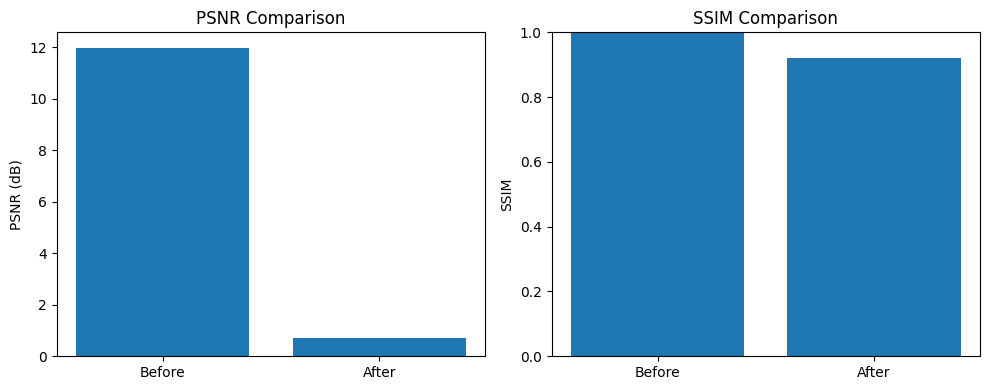

Graph saved to /content/dehazing_metrics.png


In [43]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["PSNR", "SSIM"]
before = [
    results_df["PSNR_before"].mean(),
    results_df["SSIM_before"].mean()
]
after = [
    results_df["PSNR_after"].mean(),
    results_df["SSIM_after"].mean()
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(["Before", "After"], before)
axes[0].set_title("PSNR Comparison")
axes[0].set_ylabel("PSNR (dB)")

axes[1].bar(["Before", "After"], after)
axes[1].set_title("SSIM Comparison")
axes[1].set_ylabel("SSIM")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig("/content/dehazing_metrics.png", dpi=200, bbox_inches="tight")
plt.show()

print("Graph saved to /content/dehazing_metrics.png")


In [29]:

from google.colab import files

files.download("/content/dehazing_evaluation.csv")
files.download("/content/dehazing_metrics.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

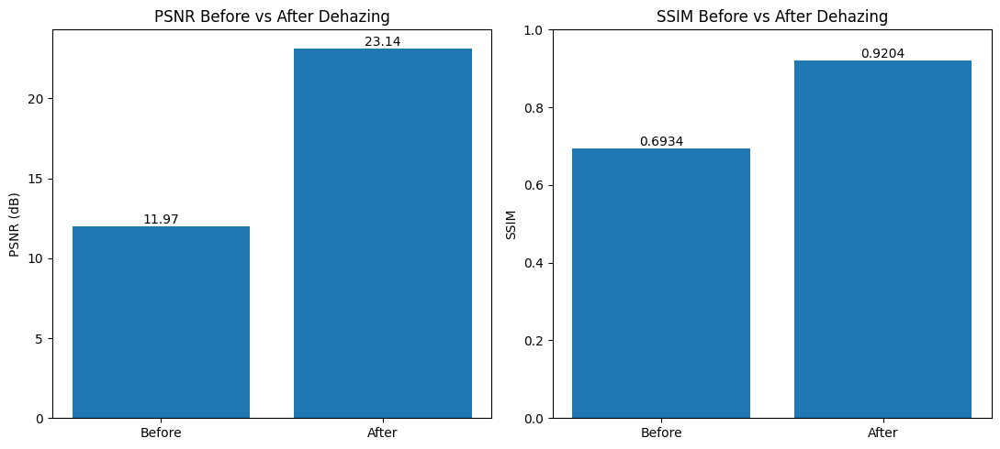

Graph created: True
Saved at: /content/dehazing_metrics.png


In [44]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load your evaluation results
results_df = pd.read_csv("/content/dehazing_evaluation.csv")

# Calculate averages
psnr_before = results_df["PSNR_before"].mean()
psnr_after = results_df["PSNR_after"].mean()
ssim_before = results_df["SSIM_before"].mean()
ssim_after = results_df["SSIM_after"].mean()

# Create two comparison graphs
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].bar(["Before", "After"], [psnr_before, psnr_after])
axes[0].set_title("PSNR Before vs After Dehazing")
axes[0].set_ylabel("PSNR (dB)")
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")

axes[1].bar(["Before", "After"], [ssim_before, ssim_after])
axes[1].set_title("SSIM Before vs After Dehazing")
axes[1].set_ylabel("SSIM")
axes[1].set_ylim(0, 1)
axes[1].bar_label(axes[1].containers[0], fmt="%.4f")

plt.tight_layout()

graph_path = "/content/dehazing_metrics.png"
plt.savefig(graph_path, dpi=200, bbox_inches="tight")
plt.show()

print("Graph created:", os.path.exists(graph_path))
print("Saved at:", graph_path)


In [31]:

from google.colab import files
files.download("/content/dehazing_metrics.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
from google.colab import files

files.download("/content/dehazing_visual_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

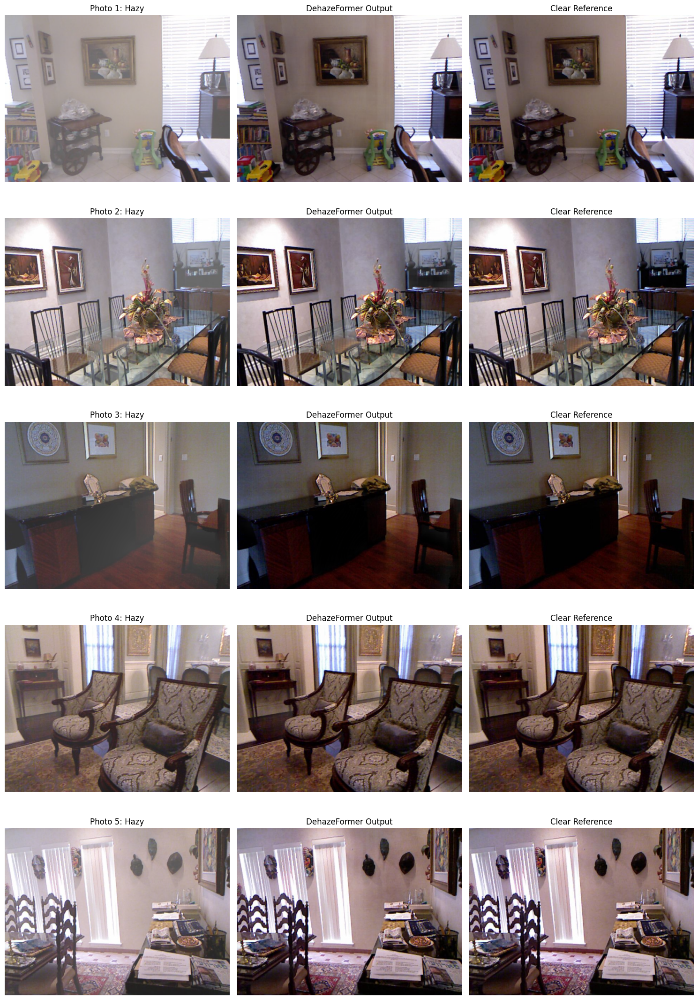

Saved: /content/dehazing_5_different_photos.png
Distinct photos displayed: 5


In [45]:
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Load evaluation results
df = pd.read_csv("/content/dehazing_evaluation.csv")

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"

# Keep only pairs whose image files exist
valid_rows = []

for _, row in df.iterrows():
    hazy_path = os.path.join(base, "hazy", row["hazy_image"])
    clear_path = os.path.join(base, "clear", row["clear_image"])

    if os.path.exists(hazy_path) and os.path.exists(clear_path):
        valid_rows.append(row)

valid_df = pd.DataFrame(valid_rows).drop_duplicates(
    subset=["clear_image"]
)

if len(valid_df) < 5:
    raise ValueError(
        f"Only {len(valid_df)} distinct clear images found. "
        "Check the dataset paths and evaluation CSV."
    )

# Randomly choose five different clear reference photos
samples = valid_df.sample(n=5, random_state=42)

fig, axes = plt.subplots(5, 3, figsize=(15, 22))
model.eval()

for i, (_, row) in enumerate(samples.iterrows()):
    hazy_path = os.path.join(base, "hazy", row["hazy_image"])
    clear_path = os.path.join(base, "clear", row["clear_image"])

    hazy_img = Image.open(hazy_path).convert("RGB")
    clear_img = Image.open(clear_path).convert("RGB")

    # Prepare hazy photo for the model
    arr = np.asarray(hazy_img, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)
    tensor = (tensor * 2 - 1).to(device)

    with torch.no_grad():
        output = model(tensor).clamp(-1, 1)

    output_img = (
        output[0].permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5
    ).clip(0, 1)

    axes[i, 0].imshow(hazy_img)
    axes[i, 0].set_title(f"Photo {i+1}: Hazy")

    axes[i, 1].imshow(output_img)
    axes[i, 1].set_title("DehazeFormer Output")

    axes[i, 2].imshow(clear_img)
    axes[i, 2].set_title("Clear Reference")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()

save_path = "/content/dehazing_5_different_photos.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)
print("Distinct photos displayed:", len(samples))

In [37]:
from google.colab import files
files.download("/content/dehazing_5_different_photos.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [47]:
import os

print("1. Evaluation CSV in /content:")
print(os.path.exists("/content/dehazing_evaluation.csv"))

print("\n2. Dataset folders:")
print(os.path.exists(
    "/content/drive/MyDrive/Dehazing_Project/rise/indoor/hazy"
))
print(os.path.exists(
    "/content/drive/MyDrive/Dehazing_Project/rise/indoor/clear"
))

print("\n3. Model checkpoint:")
print(os.path.exists(
    "/content/DehazeFormer/dehazeformer-t.pth"
))

1. Evaluation CSV in /content:
True

2. Dataset folders:
True
True

3. Model checkpoint:
True


In [48]:
import os

print("Repository exists:", os.path.exists("/content/DehazeFormer"))

if os.path.exists("/content/DehazeFormer"):
    print(os.listdir("/content/DehazeFormer")[:20])

Repository exists: True
['run.sh', 'README.md', '.gitignore', 'test.py', 'LICENSE', 'utils', 'requirements.txt', 'train.py', 'figs', 'dehazeformer-t.pth', 'models', 'datasets', '.git', 'configs']


In [49]:
%cd /content/DehazeFormer

!grep -n -i -E "pretrained|checkpoint|google drive|download|model" README.md | head -40

/content/DehazeFormer
16:Specifically, on the most frequently used SOTS indoor set, our small model outperforms FFA-Net with only 25\% \#Param and 5\% computational cost.
17:To the best of our knowledge, our large model is the first method with the PSNR over 40 dB on the SOTS indoor set, dramatically outperforming the previous state-of-the-art methods.
28:- **Apr 07, 2022:** Beta version is released, including codes, [pre-trained models](https://drive.google.com/drive/folders/1gnQiI_7Dvy-ZdQUVYXt7pW0EFQkpK39B?usp=sharing), and [RS-Haze-RGB](https://drive.google.com/drive/folders/1oaQSpdYHxEv-nMOB7yCLKfw2NDCJVtrx?usp=sharing).
48:### Download
50:You can download the pretrained models and datasets on [GoogleDrive](https://drive.google.com/drive/folders/1Yy_GH6_bydYPU6_JJzFQwig4LTh86VI4?usp=sharing) or [BaiduPan](https://pan.baidu.com/s/1WVdNccqDMnJ5k5Q__Y2dsg?pwd=gtuw) (gtuw).
57:┬─ save_models
60:│   │   └─ ... (model name)
81:Then run the following script to train the model:
84:python 

In [50]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".git", "node_modules"]]
    for file in files:
        if file.lower().endswith((".pth", ".pt")):
            print(os.path.join(root, file))

/content/DehazeFormer/dehazeformer-t.pth


In [51]:
import os
import torch

path = "/content/DehazeFormer/dehazeformer-t.pth"

print("File exists:", os.path.isfile(path))
print("File size (MB):", round(os.path.getsize(path) / (1024 * 1024), 2))

checkpoint = torch.load(path, map_location="cpu", weights_only=False)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:20])
    if "state_dict" in checkpoint:
        print("State dict keys:", list(checkpoint["state_dict"].keys())[:5])

File exists: True
File size (MB): 2.9
Checkpoint type: <class 'dict'>
Checkpoint keys: ['state_dict']
State dict keys: ['module.patch_embed.proj.weight', 'module.patch_embed.proj.bias', 'module.layer1.blocks.0.attn.conv.weight', 'module.layer1.blocks.0.attn.conv.bias', 'module.layer1.blocks.0.attn.V.weight']


In [52]:
%cd /content/DehazeFormer

import torch
from collections import OrderedDict
from models import dehazeformer_t

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Create the model
model = dehazeformer_t()

# Load checkpoint
checkpoint = torch.load(
    "/content/DehazeFormer/dehazeformer-t.pth",
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["state_dict"]

# Remove the 'module.' prefix
state_dict = OrderedDict(
    (key[7:] if key.startswith("module.") else key, value)
    for key, value in state_dict.items()
)

# Load pretrained weights
model.load_state_dict(state_dict)

# Prepare for inference
model = model.to(device)
model.eval()

print("DehazeFormer-T loaded successfully!")
print("Device:", device)

/content/DehazeFormer
Using device: cuda
DehazeFormer-T loaded successfully!
Device: cuda


In [53]:
import os

hazy_dir = "/content/drive/MyDrive/Dehazing_Project/rise/indoor/hazy"

print("Folder exists:", os.path.isdir(hazy_dir))

if os.path.isdir(hazy_dir):
    images = [
        f for f in os.listdir(hazy_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
    ]
    images.sort()

    print("Number of hazy images:", len(images))
    print("First 10 images:", images[:10])

Folder exists: True
Number of hazy images: 500
First 10 images: ['1400_1.png', '1400_10.png', '1400_2.png', '1400_3.png', '1400_4.png', '1400_5.png', '1400_6.png', '1400_7.png', '1400_8.png', '1400_9.png']


In [54]:
import os
import inspect

print("Test script:", os.path.exists("/content/DehazeFormer/test.py"))

with open("/content/DehazeFormer/test.py", "r") as f:
    print(f.read()[:10000])

Test script: True
import os
import argparse
import torch
import torch.nn as nn
import torch.nn.functional as F
from pytorch_msssim import ssim
from torch.utils.data import DataLoader
from collections import OrderedDict

from utils import AverageMeter, write_img, chw_to_hwc
from datasets.loader import PairLoader
from models import *


parser = argparse.ArgumentParser()
parser.add_argument('--model', default='dehazeformer-s', type=str, help='model name')
parser.add_argument('--num_workers', default=16, type=int, help='number of workers')
parser.add_argument('--data_dir', default='./data/', type=str, help='path to dataset')
parser.add_argument('--save_dir', default='./saved_models/', type=str, help='path to models saving')
parser.add_argument('--result_dir', default='./results/', type=str, help='path to results saving')
parser.add_argument('--dataset', default='RESIDE-IN', type=str, help='dataset name')
parser.add_argument('--exp', default='indoor', type=str, help='experiment setting')
ar

In [55]:
%cd /content/DehazeFormer

with open("datasets/loader.py", "r") as f:
    code = f.read()

print(code[:12000])

/content/DehazeFormer
import os
import random
import numpy as np
import cv2

from torch.utils.data import Dataset
from utils import hwc_to_chw, read_img


def augment(imgs=[], size=256, edge_decay=0., only_h_flip=False):
	H, W, _ = imgs[0].shape
	Hc, Wc = [size, size]

	# simple re-weight for the edge
	if random.random() < Hc / H * edge_decay:
		Hs = 0 if random.randint(0, 1) == 0 else H - Hc
	else:
		Hs = random.randint(0, H-Hc)

	if random.random() < Wc / W * edge_decay:
		Ws = 0 if random.randint(0, 1) == 0 else W - Wc
	else:
		Ws = random.randint(0, W-Wc)

	for i in range(len(imgs)):
		imgs[i] = imgs[i][Hs:(Hs+Hc), Ws:(Ws+Wc), :]

	# horizontal flip
	if random.randint(0, 1) == 1:
		for i in range(len(imgs)):
			imgs[i] = np.flip(imgs[i], axis=1)

	if not only_h_flip:
		# bad data augmentations for outdoor
		rot_deg = random.randint(0, 3)
		for i in range(len(imgs)):
			imgs[i] = np.rot90(imgs[i], rot_deg, (0, 1))
			
	return imgs


def align(imgs=[], size=256):
	H, W, _ = imgs[0].s

Testing image: 1400_1.png


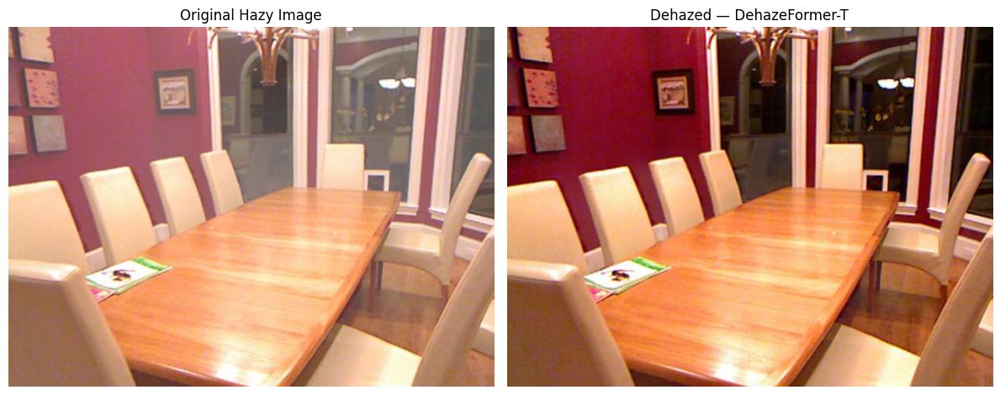

Saved dehazed image: /content/dehazing_results/1400_1_dehazed.png


In [56]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Dataset folder
hazy_dir = "/content/drive/MyDrive/Dehazing_Project/rise/indoor/hazy"

# Find images
image_paths = sorted(
    p for p in glob.glob(os.path.join(hazy_dir, "*"))
    if p.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
)

if not image_paths:
    raise FileNotFoundError(f"No images found in {hazy_dir}")

# Select first image
image_path = image_paths[0]
print("Testing image:", os.path.basename(image_path))

# Load and preprocess as expected by DehazeFormer
image = Image.open(image_path).convert("RGB")
original_size = image.size
image_np = np.asarray(image).astype(np.float32) / 255.0

input_tensor = torch.from_numpy(image_np).permute(2, 0, 1).unsqueeze(0)
input_tensor = input_tensor * 2.0 - 1.0
input_tensor = input_tensor.to(device)

# Inference
model.eval()
with torch.no_grad():
    output = model(input_tensor).clamp(-1, 1)
    output = (output * 0.5 + 0.5).clamp(0, 1)

# Convert to displayable RGB
dehazed = output[0].permute(1, 2, 0).cpu().numpy()

# Display
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_np)
plt.title("Original Hazy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dehazed)
plt.title("Dehazed — DehazeFormer-T")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
output_dir = "/content/dehazing_results"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    os.path.splitext(os.path.basename(image_path))[0] + "_dehazed.png"
)

Image.fromarray(
    (dehazed * 255).round().astype(np.uint8)
).save(output_path)

print("Saved dehazed image:", output_path)

In [57]:
import os
import pandas as pd

metadata_path = (
    "/content/drive/MyDrive/Dehazing_Project/rise/metadata_indoor.csv"
)

print("Metadata exists:", os.path.exists(metadata_path))

if os.path.exists(metadata_path):
    metadata = pd.read_csv(metadata_path)
    print("\nColumns:", metadata.columns.tolist())
    print("\nNumber of rows:", len(metadata))
    display(metadata.head(5))

Metadata exists: True

Columns: ['image_id', 'clear_image_path', 'hazy_image_paths']

Number of rows: 50


,image_id,clear_image_path,hazy_image_paths
0,1400,clear/1400.png,"['hazy/1400_1.png', 'hazy/1400_2.png', 'hazy/1..."
1,1401,clear/1401.png,"['hazy/1401_1.png', 'hazy/1401_2.png', 'hazy/1..."
2,1402,clear/1402.png,"['hazy/1402_1.png', 'hazy/1402_2.png', 'hazy/1..."
3,1403,clear/1403.png,"['hazy/1403_1.png', 'hazy/1403_2.png', 'hazy/1..."
4,1404,clear/1404.png,"['hazy/1404_1.png', 'hazy/1404_2.png', 'hazy/1..."


In [58]:
import os
import ast
import time
import cv2
import torch
import numpy as np
import pandas as pd

from PIL import Image
from collections import OrderedDict
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# --------------------------------------------------
# 1. Paths and model setup
# --------------------------------------------------
repo = "/content/DehazeFormer"
base_dir = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"
metadata_path = "/content/drive/MyDrive/Dehazing_Project/rise/metadata_indoor.csv"
checkpoint_path = os.path.join(repo, "dehazeformer-t.pth")

assert os.path.isfile(metadata_path), f"Metadata not found: {metadata_path}"
assert os.path.isdir(base_dir), f"Dataset folder not found: {base_dir}"
assert os.path.isfile(checkpoint_path), f"Checkpoint not found: {checkpoint_path}"

%cd /content/DehazeFormer

# Reuse the model if it is already loaded; otherwise load it.
if "model" not in globals():
    from models import dehazeformer_t

    model = dehazeformer_t()
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    state_dict = checkpoint["state_dict"]

    state_dict = OrderedDict(
        (k[7:] if k.startswith("module.") else k, v)
        for k, v in state_dict.items()
    )
    model.load_state_dict(state_dict)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# --------------------------------------------------
# 2. Dark Channel Prior (DCP)
# --------------------------------------------------
def dark_channel(image, patch_size=15):
    # image is RGB, float32, range [0, 1]
    min_rgb = np.min(image, axis=2)
    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (patch_size, patch_size)
    )
    return cv2.erode(min_rgb, kernel)

def dehaze_dcp(image, patch_size=15, omega=0.95, t0=0.1):
    image = np.asarray(image, dtype=np.float32)
    image = np.clip(image, 0, 1)

    dark = dark_channel(image, patch_size)

    # Estimate atmospheric light from the brightest dark-channel pixels.
    flat_dark = dark.ravel()
    flat_image = image.reshape(-1, 3)
    count = max(1, int(flat_dark.size * 0.001))
    indices = np.argpartition(flat_dark, -count)[-count:]
    atmospheric_light = flat_image[indices][
        np.argmax(np.sum(flat_image[indices], axis=1))
    ]
    atmospheric_light = np.maximum(atmospheric_light, 1e-3)

    normalized = image / atmospheric_light.reshape(1, 1, 3)
    transmission = 1 - omega * dark_channel(normalized, patch_size)
    transmission = np.maximum(transmission, t0)

    result = (
        image - atmospheric_light.reshape(1, 1, 3)
    ) / transmission[:, :, None] + atmospheric_light.reshape(1, 1, 3)

    return np.clip(result, 0, 1)

# --------------------------------------------------
# 3. Read metadata and validate pairs
# --------------------------------------------------
metadata = pd.read_csv(metadata_path)
records = []

for _, row in metadata.iterrows():
    clear_rel = row["clear_image_path"]
    clear_path = os.path.join(base_dir, clear_rel)

    hazy_paths = ast.literal_eval(row["hazy_image_paths"])

    if not os.path.isfile(clear_path):
        continue

    for hazy_rel in hazy_paths:
        hazy_path = os.path.join(base_dir, hazy_rel)

        if os.path.isfile(hazy_path):
            records.append({
                "image_id": row["image_id"],
                "hazy_path": hazy_path,
                "clear_path": clear_path,
                "hazy_name": os.path.basename(hazy_path)
            })

print("Metadata rows:", len(metadata))
print("Valid hazy/clear pairs:", len(records))

if not records:
    raise RuntimeError("No valid pairs found. Check the dataset paths.")

# --------------------------------------------------
# 4. Evaluate both methods on identical pairs
# --------------------------------------------------
results = []
output_dir = "/content/dcp_vs_dehazeformer"
os.makedirs(output_dir, exist_ok=True)

def sync_device():
    if device.type == "cuda":
        torch.cuda.synchronize()

for i, record in enumerate(records, start=1):
    try:
        hazy_pil = Image.open(record["hazy_path"]).convert("RGB")
        clear_pil = Image.open(record["clear_path"]).convert("RGB")

        # Align input/reference dimensions if necessary.
        if hazy_pil.size != clear_pil.size:
            hazy_pil = hazy_pil.resize(
                clear_pil.size, Image.Resampling.LANCZOS
            )

        hazy = np.asarray(hazy_pil, dtype=np.float32) / 255.0
        clear = np.asarray(clear_pil, dtype=np.float32) / 255.0

        # DCP runtime and output
        start = time.perf_counter()
        dcp_output = dehaze_dcp(hazy)
        dcp_seconds = time.perf_counter() - start

        # DehazeFormer runtime (includes tensor preparation and inference)
        input_tensor = torch.from_numpy(hazy).permute(2, 0, 1)
        input_tensor = input_tensor.unsqueeze(0).to(device)
        input_tensor = input_tensor * 2.0 - 1.0

        sync_device()
        start = time.perf_counter()

        with torch.inference_mode():
            output_tensor = model(input_tensor).clamp(-1, 1)
            output_tensor = (output_tensor * 0.5 + 0.5).clamp(0, 1)

        sync_device()
        former_seconds = time.perf_counter() - start

        former_output = (
            output_tensor[0].permute(1, 2, 0).cpu().numpy()
        )

        # Calculate metrics against the same clear reference
        dcp_psnr = peak_signal_noise_ratio(
            clear, dcp_output, data_range=1.0
        )
        former_psnr = peak_signal_noise_ratio(
            clear, former_output, data_range=1.0
        )

        dcp_ssim = structural_similarity(
            clear, dcp_output, data_range=1.0, channel_axis=2
        )
        former_ssim = structural_similarity(
            clear, former_output, data_range=1.0, channel_axis=2
        )

        results.append({
            "image_id": record["image_id"],
            "hazy_image": record["hazy_name"],
            "DCP_PSNR_dB": dcp_psnr,
            "DCP_SSIM": dcp_ssim,
            "DCP_runtime_s": dcp_seconds,
            "DehazeFormer_PSNR_dB": former_psnr,
            "DehazeFormer_SSIM": former_ssim,
            "DehazeFormer_runtime_s": former_seconds
        })

        # Save a sample comparison for visual inspection.
        if i <= 5:
            comparison = np.concatenate(
                [hazy, dcp_output, former_output, clear], axis=1
            )
            save_path = os.path.join(
                output_dir, f"comparison_{i:02d}.png"
            )
            Image.fromarray(
                (np.clip(comparison, 0, 1) * 255).round().astype(np.uint8)
            ).save(save_path)

        if i % 10 == 0 or i == len(records):
            print(f"Processed {i}/{len(records)} pairs")

    except Exception as e:
        print(f"Skipped {record['hazy_name']}: {e}")

# --------------------------------------------------
# 5. Save per-image results and summary table
# --------------------------------------------------
if not results:
    raise RuntimeError("No images were evaluated successfully.")

df = pd.DataFrame(results)
csv_path = os.path.join(output_dir, "per_image_results.csv")
df.to_csv(csv_path, index=False)

summary = pd.DataFrame([
    {
        "Method": "Dark Channel Prior (DCP)",
        "Mean PSNR (dB) ↑": df["DCP_PSNR_dB"].mean(),
        "Mean SSIM ↑": df["DCP_SSIM"].mean(),
        "Mean runtime (s/image) ↓": df["DCP_runtime_s"].mean()
    },
    {
        "Method": "DehazeFormer-T",
        "Mean PSNR (dB) ↑": df["DehazeFormer_PSNR_dB"].mean(),
        "Mean SSIM ↑": df["DehazeFormer_SSIM"].mean(),
        "Mean runtime (s/image) ↓": df["DehazeFormer_runtime_s"].mean()
    }
])

summary_path = os.path.join(output_dir, "summary_comparison.csv")
summary.to_csv(summary_path, index=False)

print("\n========== FINAL COMPARISON ==========")
display(summary.round(4))

print("Successful pairs:", len(df))
print("Per-image CSV:", csv_path)
print("Summary CSV:", summary_path)
print("Sample comparisons:", output_dir)

/content/DehazeFormer
Device: cuda
GPU: Tesla T4
Metadata rows: 50
Valid hazy/clear pairs: 500
Processed 10/500 pairs
Processed 20/500 pairs
Processed 30/500 pairs
Processed 40/500 pairs
Processed 50/500 pairs
Processed 60/500 pairs
Processed 70/500 pairs
Processed 80/500 pairs
Processed 90/500 pairs
Processed 100/500 pairs
Processed 110/500 pairs
Processed 120/500 pairs
Processed 130/500 pairs
Processed 140/500 pairs
Processed 150/500 pairs
Processed 160/500 pairs
Processed 170/500 pairs
Processed 180/500 pairs
Processed 190/500 pairs
Processed 200/500 pairs
Processed 210/500 pairs
Processed 220/500 pairs
Processed 230/500 pairs
Processed 240/500 pairs
Processed 250/500 pairs
Processed 260/500 pairs
Processed 270/500 pairs
Processed 280/500 pairs
Processed 290/500 pairs
Processed 300/500 pairs
Processed 310/500 pairs
Processed 320/500 pairs
Processed 330/500 pairs
Processed 340/500 pairs
Processed 350/500 pairs
Processed 360/500 pairs
Processed 370/500 pairs
Processed 380/500 pairs
Pr

,Method,Mean PSNR (dB) ↑,Mean SSIM ↑,Mean runtime (s/image) ↓
0,Dark Channel Prior (DCP),17.9447,0.7773,0.036
1,DehazeFormer-T,23.1431,0.9204,0.098


Successful pairs: 500
Per-image CSV: /content/dcp_vs_dehazeformer/per_image_results.csv
Summary CSV: /content/dcp_vs_dehazeformer/summary_comparison.csv
Sample comparisons: /content/dcp_vs_dehazeformer


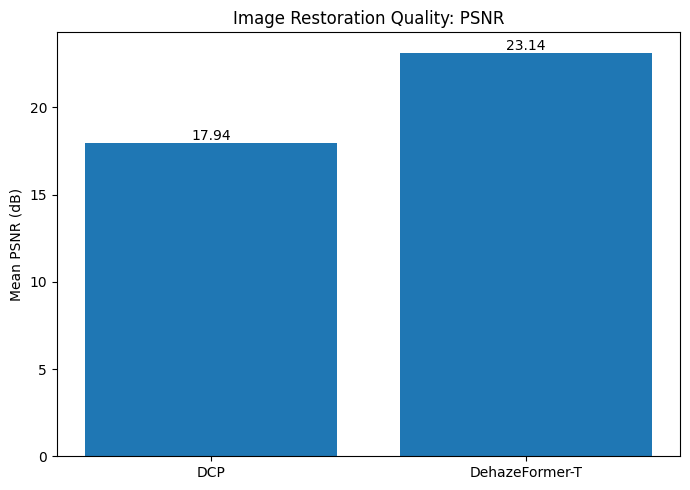

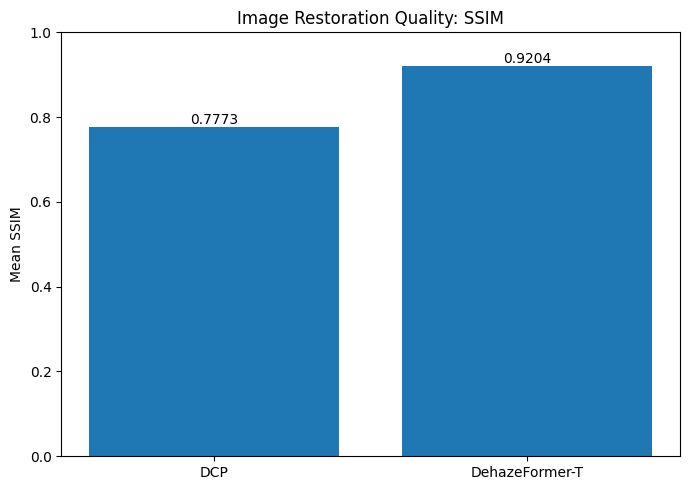

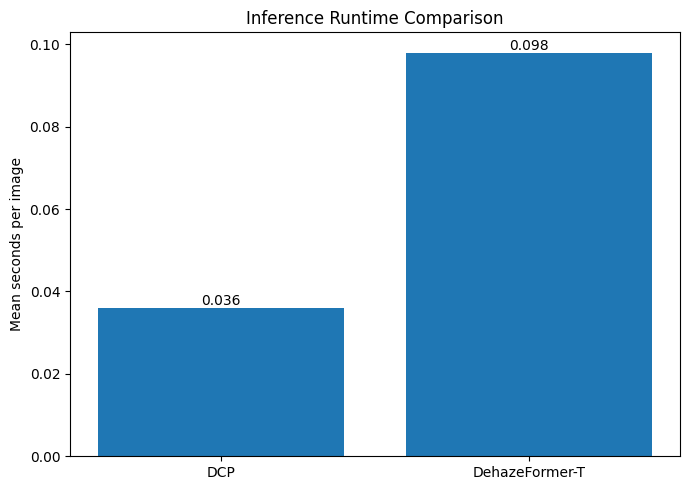

Saved all three graphs in: /content/dcp_vs_dehazeformer


In [59]:
import os
import pandas as pd
import matplotlib.pyplot as plt

results_dir = "/content/dcp_vs_dehazeformer"
df = pd.read_csv(os.path.join(results_dir, "per_image_results.csv"))

# Calculate summary from the per-image results
methods = ["DCP", "DehazeFormer-T"]

psnr_values = [
    df["DCP_PSNR_dB"].mean(),
    df["DehazeFormer_PSNR_dB"].mean()
]
ssim_values = [
    df["DCP_SSIM"].mean(),
    df["DehazeFormer_SSIM"].mean()
]
runtime_values = [
    df["DCP_runtime_s"].mean(),
    df["DehazeFormer_runtime_s"].mean()
]

# Graph 1: PSNR
plt.figure(figsize=(7, 5))
bars = plt.bar(methods, psnr_values)
plt.ylabel("Mean PSNR (dB)")
plt.title("Image Restoration Quality: PSNR")
plt.bar_label(bars, fmt="%.2f")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "psnr_comparison.png"), dpi=300)
plt.show()

# Graph 2: SSIM
plt.figure(figsize=(7, 5))
bars = plt.bar(methods, ssim_values)
plt.ylabel("Mean SSIM")
plt.title("Image Restoration Quality: SSIM")
plt.ylim(0, 1)
plt.bar_label(bars, fmt="%.4f")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "ssim_comparison.png"), dpi=300)
plt.show()

# Graph 3: Runtime
plt.figure(figsize=(7, 5))
bars = plt.bar(methods, runtime_values)
plt.ylabel("Mean seconds per image")
plt.title("Inference Runtime Comparison")
plt.bar_label(bars, fmt="%.3f")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "runtime_comparison.png"), dpi=300)
plt.show()

print("Saved all three graphs in:", results_dir)

In [60]:
import os
import shutil

source = "/content/dcp_vs_dehazeformer"
destination = "/content/drive/MyDrive/Dehazing_Project/results"

os.makedirs(destination, exist_ok=True)
shutil.copytree(source, destination, dirs_exist_ok=True)

print("Results saved to:", destination)
print(os.listdir(destination))

Results saved to: /content/drive/MyDrive/Dehazing_Project/results
['psnr_comparison.png', 'comparison_03.png', 'comparison_05.png', 'per_image_results.csv', 'runtime_comparison.png', 'comparison_02.png', 'ssim_comparison.png', 'summary_comparison.csv', 'comparison_04.png', 'comparison_01.png']


In [61]:
import os
import ast
import pandas as pd
import numpy as np
import torch
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"
meta_path = "/content/drive/MyDrive/Dehazing_Project/rise/metadata_indoor.csv"
checkpoint_path = "/content/DehazeFormer/dehazeformer-t.pth"

# 1. Check checkpoint
print("=== CHECKPOINT ===")
print("Exists:", os.path.isfile(checkpoint_path))
if os.path.isfile(checkpoint_path):
    print("Size (MB):", round(os.path.getsize(checkpoint_path) / 1e6, 2))

checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
print("Checkpoint keys:", list(checkpoint.keys()))

# 2. Check dataset pairings
print("\n=== DATASET ===")
metadata = pd.read_csv(meta_path)
valid_pairs = []

for _, row in metadata.iterrows():
    clear_path = os.path.join(base, row["clear_image_path"])
    hazy_paths = ast.literal_eval(row["hazy_image_paths"])

    for rel_path in hazy_paths:
        hazy_path = os.path.join(base, rel_path)
        if os.path.isfile(clear_path) and os.path.isfile(hazy_path):
            valid_pairs.append((hazy_path, clear_path))

print("Metadata rows:", len(metadata))
print("Valid pairs:", len(valid_pairs))
print("Unique clear images:", len(set(c for _, c in valid_pairs)))
print("First 3 pairs:")
for hazy_path, clear_path in valid_pairs[:3]:
    print(os.path.basename(hazy_path), "<->", os.path.basename(clear_path))

# 3. Check model output and metrics on one pair
print("\n=== SAMPLE EVALUATION ===")
hazy_path, clear_path = valid_pairs[0]

hazy_pil = Image.open(hazy_path).convert("RGB")
clear_pil = Image.open(clear_path).convert("RGB")

print("Hazy dimensions:", hazy_pil.size)
print("Clear dimensions:", clear_pil.size)

if hazy_pil.size != clear_pil.size:
    hazy_pil = hazy_pil.resize(
        clear_pil.size, Image.Resampling.LANCZOS
    )
    print("WARNING: Hazy image resized to match reference.")

hazy = np.asarray(hazy_pil, dtype=np.float32) / 255.0
clear = np.asarray(clear_pil, dtype=np.float32) / 255.0

device = next(model.parameters()).device
tensor = torch.from_numpy(hazy).permute(2, 0, 1).unsqueeze(0)
tensor = tensor.to(device) * 2.0 - 1.0

model.eval()
with torch.inference_mode():
    prediction = model(tensor).clamp(-1, 1)
    prediction = (prediction * 0.5 + 0.5).clamp(0, 1)

output = prediction[0].permute(1, 2, 0).cpu().numpy()

print("Model output shape:", output.shape)
print("Output range:", float(output.min()), "to", float(output.max()))
print("Hazy input PSNR:", round(
    peak_signal_noise_ratio(clear, hazy, data_range=1.0), 3
))
print("Dehazed output PSNR:", round(
    peak_signal_noise_ratio(clear, output, data_range=1.0), 3
))
print("Dehazed output SSIM:", round(
    structural_similarity(clear, output, data_range=1.0, channel_axis=2), 4
))

=== CHECKPOINT ===
Exists: True
Size (MB): 3.05
Checkpoint keys: ['state_dict']

=== DATASET ===
Metadata rows: 50
Valid pairs: 500
Unique clear images: 50
First 3 pairs:
1400_1.png <-> 1400.png
1400_2.png <-> 1400.png
1400_3.png <-> 1400.png

=== SAMPLE EVALUATION ===
Hazy dimensions: (620, 460)
Clear dimensions: (620, 460)
Model output shape: (460, 620, 3)
Output range: 0.0 to 1.0
Hazy input PSNR: 14.785
Dehazed output PSNR: 29.734
Dehazed output SSIM: 0.9645


In [62]:
import pandas as pd
import os

csv_path = "/content/dcp_vs_dehazeformer/per_image_results.csv"
df = pd.read_csv(csv_path)

print("Number of evaluated images:", len(df))

print("\n=== DehazeFormer PSNR distribution ===")
print(df["DehazeFormer_PSNR_dB"].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
).round(3))

print("\n=== 10 worst DehazeFormer results ===")
display(
    df.sort_values("DehazeFormer_PSNR_dB")[
        ["hazy_image", "DCP_PSNR_dB", "DehazeFormer_PSNR_dB",
         "DCP_SSIM", "DehazeFormer_SSIM"]
    ].head(10).round(4)
)

print("\n=== 10 best DehazeFormer results ===")
display(
    df.sort_values("DehazeFormer_PSNR_dB", ascending=False)[
        ["hazy_image", "DCP_PSNR_dB", "DehazeFormer_PSNR_dB",
         "DCP_SSIM", "DehazeFormer_SSIM"]
    ].head(10).round(4)
)

Number of evaluated images: 500

=== DehazeFormer PSNR distribution ===
count    500.000
mean      23.143
std        4.022
min       14.210
5%        16.976
25%       20.139
50%       22.912
75%       26.023
95%       29.824
max       33.879
Name: DehazeFormer_PSNR_dB, dtype: float64

=== 10 worst DehazeFormer results ===


,hazy_image,DCP_PSNR_dB,DehazeFormer_PSNR_dB,DCP_SSIM,DehazeFormer_SSIM
319,1431_10.png,21.9498,14.2096,0.7839,0.7085
409,1440_10.png,18.8880,14.7380,0.8108,0.8535
209,1420_10.png,18.6733,14.7567,0.7917,0.8126
318,1431_9.png,22.2220,15.2203,0.7923,0.7310
489,1448_10.png,20.2103,15.3351,0.8182,0.8474
139,1413_10.png,17.7637,15.6538,0.7482,0.8215
159,1415_10.png,16.0942,15.6940,0.7112,0.8520
488,1448_9.png,20.1286,15.8449,0.8204,0.8577
408,1440_9.png,18.4474,15.9512,0.8070,0.8788
499,1449_10.png,21.2314,16.2134,0.8281,0.8628



=== 10 best DehazeFormer results ===


,hazy_image,DCP_PSNR_dB,DehazeFormer_PSNR_dB,DCP_SSIM,DehazeFormer_SSIM
220,1422_1.png,19.3319,33.8795,0.7545,0.9636
350,1435_1.png,16.8565,33.7611,0.8365,0.9808
440,1444_1.png,21.5981,33.2792,0.8254,0.9518
221,1422_2.png,19.4025,32.4933,0.7413,0.9594
351,1435_2.png,17.0557,32.3552,0.8355,0.9757
280,1428_1.png,17.3682,32.2399,0.7970,0.9575
250,1425_1.png,20.8492,32.2048,0.8467,0.9756
10,1401_1.png,18.4537,31.9229,0.8197,0.9588
441,1444_2.png,21.6492,31.7663,0.8134,0.9435
180,1418_1.png,15.2580,31.7124,0.8016,0.9797


In [63]:
import pandas as pd

csv_path = "/content/dcp_vs_dehazeformer/per_image_results.csv"
df = pd.read_csv(csv_path)

# Extract haze version from filenames such as 1431_10.png
df["haze_level"] = (
    df["hazy_image"]
    .str.extract(r"_(\d+)\.png$", expand=False)
    .astype(int)
)

# Compare average performance across versions
summary = df.groupby("haze_level").agg(
    image_count=("DehazeFormer_PSNR_dB", "count"),
    dehazeformer_psnr=("DehazeFormer_PSNR_dB", "mean"),
    dcp_psnr=("DCP_PSNR_dB", "mean"),
    dehazeformer_ssim=("DehazeFormer_SSIM", "mean"),
    dcp_ssim=("DCP_SSIM", "mean")
).round(3)

print("=== Performance by haze version ===")
display(summary)

# Compare the difference between the methods
df["psnr_difference"] = (
    df["DehazeFormer_PSNR_dB"] - df["DCP_PSNR_dB"]
)

print("\n=== Images where DehazeFormer performs worse than DCP ===")
worse = df[df["psnr_difference"] < 0]

print("Number of images:", len(worse))
print("Percentage:", round(len(worse) / len(df) * 100, 2), "%")

display(
    worse.sort_values("psnr_difference")[
        ["hazy_image", "DCP_PSNR_dB",
         "DehazeFormer_PSNR_dB", "psnr_difference"]
    ].head(15).round(3)
)

=== Performance by haze version ===


,image_count,dehazeformer_psnr,dcp_psnr,dehazeformer_ssim,dcp_ssim
haze_level,,,,,
1,50,28.208,17.617,0.961,0.791
2,50,26.819,17.715,0.953,0.788
3,50,25.610,17.796,0.945,0.784
4,50,24.522,17.861,0.937,0.781
5,50,23.483,17.928,0.928,0.778
6,50,22.500,18.019,0.919,0.776
7,50,21.525,18.061,0.908,0.773
8,50,20.526,18.115,0.897,0.770
9,50,19.576,18.157,0.885,0.768



=== Images where DehazeFormer performs worse than DCP ===
Number of images: 84
Percentage: 16.8 %


,hazy_image,DCP_PSNR_dB,DehazeFormer_PSNR_dB,psnr_difference
319,1431_10.png,21.950,14.210,-7.740
318,1431_9.png,22.222,15.220,-7.002
317,1431_8.png,22.456,16.294,-6.162
316,1431_7.png,22.657,17.639,-5.018
499,1449_10.png,21.231,16.213,-5.018
489,1448_10.png,20.210,15.335,-4.875
329,1432_10.png,20.996,16.310,-4.685
498,1449_9.png,21.142,16.692,-4.450
488,1448_9.png,20.129,15.845,-4.284
328,1432_9.png,21.020,16.804,-4.216


In [64]:
import os
import pandas as pd
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio
from IPython.display import display

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"
hazy_dir = os.path.join(base, "hazy")
clear_dir = os.path.join(base, "clear")

df = pd.read_csv(
    "/content/dcp_vs_dehazeformer/per_image_results.csv"
)

records = []

for _, row in df.iterrows():
    hazy_name = row["hazy_image"]

    # Example: 1431_10.png -> clear image 1431.png
    clear_name = hazy_name.rsplit("_", 1)[0] + ".png"

    hazy_path = os.path.join(hazy_dir, hazy_name)
    clear_path = os.path.join(clear_dir, clear_name)

    if not os.path.exists(hazy_path) or not os.path.exists(clear_path):
        continue

    hazy = np.asarray(
        Image.open(hazy_path).convert("RGB")
    ).astype(np.float32) / 255.0

    clear = np.asarray(
        Image.open(clear_path).convert("RGB")
    ).astype(np.float32) / 255.0

    if hazy.shape != clear.shape:
        print("Skipping mismatched dimensions:", hazy_name)
        continue

    input_psnr = peak_signal_noise_ratio(
        clear, hazy, data_range=1.0
    )

    records.append({
        "hazy_image": hazy_name,
        "haze_level": int(hazy_name.rsplit("_", 1)[1].replace(".png", "")),
        "input_psnr": input_psnr,
        "dcp_psnr": row["DCP_PSNR_dB"],
        "dehazeformer_psnr": row["DehazeFormer_PSNR_dB"],
    })

audit = pd.DataFrame(records)

audit["dcp_improvement"] = audit["dcp_psnr"] - audit["input_psnr"]
audit["dehazeformer_improvement"] = (
    audit["dehazeformer_psnr"] - audit["input_psnr"]
)

summary = audit.groupby("haze_level").agg(
    images=("hazy_image", "count"),
    input_psnr=("input_psnr", "mean"),
    dcp_psnr=("dcp_psnr", "mean"),
    dehazeformer_psnr=("dehazeformer_psnr", "mean"),
    dcp_gain=("dcp_improvement", "mean"),
    dehazeformer_gain=("dehazeformer_improvement", "mean"),
).round(3)

print("=== Input quality and improvement by version ===")
display(summary)

=== Input quality and improvement by version ===


,images,input_psnr,dcp_psnr,dehazeformer_psnr,dcp_gain,dehazeformer_gain
haze_level,,,,,,
1,50,15.428,17.617,28.208,2.189,12.780
2,50,14.335,17.715,26.819,3.380,12.484
3,50,13.417,17.796,25.610,4.379,12.193
4,50,12.632,17.861,24.522,5.229,11.891
5,50,11.950,17.928,23.483,5.978,11.533
6,50,11.352,18.019,22.500,6.667,11.148
7,50,10.822,18.061,21.525,7.239,10.703
8,50,10.349,18.115,20.526,7.766,10.177
9,50,9.924,18.157,19.576,8.233,9.652


In [65]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "/content/dcp_vs_dehazeformer/per_image_results.csv"
)

# Each group represents one original clear scene
df["scene_id"] = df["hazy_image"].str.rsplit("_", n=1).str[0]

# Average the 10 haze versions within each scene
scene_results = df.groupby("scene_id").agg(
    dehazeformer_psnr=("DehazeFormer_PSNR_dB", "mean"),
    dcp_psnr=("DCP_PSNR_dB", "mean"),
    dehazeformer_ssim=("DehazeFormer_SSIM", "mean"),
    dcp_ssim=("DCP_SSIM", "mean"),
)

scene_results["psnr_difference"] = (
    scene_results["dehazeformer_psnr"] - scene_results["dcp_psnr"]
)

scene_results["ssim_difference"] = (
    scene_results["dehazeformer_ssim"] - scene_results["dcp_ssim"]
)

# Bootstrap the 50 scenes, not the 500 individual image pairs
rng = np.random.default_rng(42)
differences = scene_results["psnr_difference"].to_numpy()

bootstrap_means = np.array([
    rng.choice(differences, size=len(differences), replace=True).mean()
    for _ in range(10000)
])

ci_low, ci_high = np.percentile(bootstrap_means, [2.5, 97.5])

print("Number of independent clear scenes:", len(scene_results))
print("Mean scene-level PSNR difference:", round(differences.mean(), 3), "dB")
print("95% bootstrap confidence interval:",
      (round(ci_low, 3), round(ci_high, 3)), "dB")

print("Scenes where DehazeFormer-T has higher mean PSNR:",
      int((differences > 0).sum()), "out of", len(differences))

print("Mean scene-level SSIM difference:",
      round(scene_results["ssim_difference"].mean(), 4))

print("\nScenes with the largest PSNR disadvantage:")
display(
    scene_results.sort_values("psnr_difference")[
        ["dehazeformer_psnr", "dcp_psnr", "psnr_difference"]
    ].head(10).round(3)
)

Number of independent clear scenes: 50
Mean scene-level PSNR difference: 5.198 dB
95% bootstrap confidence interval: (np.float64(4.111), np.float64(6.235)) dB
Scenes where DehazeFormer-T has higher mean PSNR: 44 out of 50
Mean scene-level SSIM difference: 0.143

Scenes with the largest PSNR disadvantage:


,dehazeformer_psnr,dcp_psnr,psnr_difference
scene_id,,,
1431,19.330,22.761,-3.431
1432,19.213,20.957,-1.744
1449,19.349,20.596,-1.247
1448,18.672,19.762,-1.090
1402,22.215,22.611,-0.396
1446,20.394,20.681,-0.288
1430,20.909,20.846,0.064
1433,19.954,19.658,0.296
1445,20.836,19.799,1.037


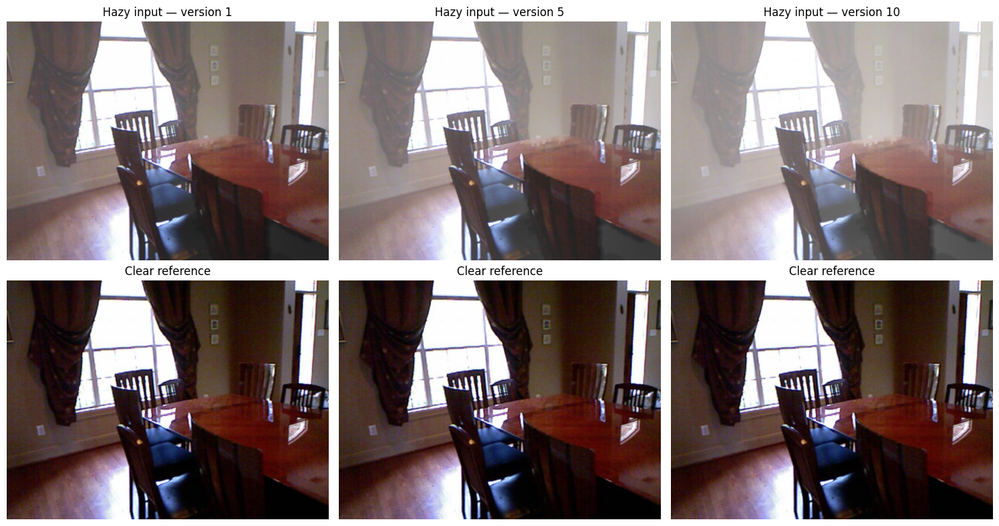

In [66]:
import os
import matplotlib.pyplot as plt
from PIL import Image

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"
hazy_dir = os.path.join(base, "hazy")
clear_dir = os.path.join(base, "clear")

scene_id = "1431"
versions = [1, 5, 10]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, version in enumerate(versions):
    hazy_name = f"{scene_id}_{version}.png"
    hazy_path = os.path.join(hazy_dir, hazy_name)

    hazy = Image.open(hazy_path).convert("RGB")
    axes[0, col].imshow(hazy)
    axes[0, col].set_title(f"Hazy input — version {version}")
    axes[0, col].axis("off")

    clear_path = os.path.join(clear_dir, f"{scene_id}.png")
    clear = Image.open(clear_path).convert("RGB")
    axes[1, col].imshow(clear)
    axes[1, col].set_title("Clear reference")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

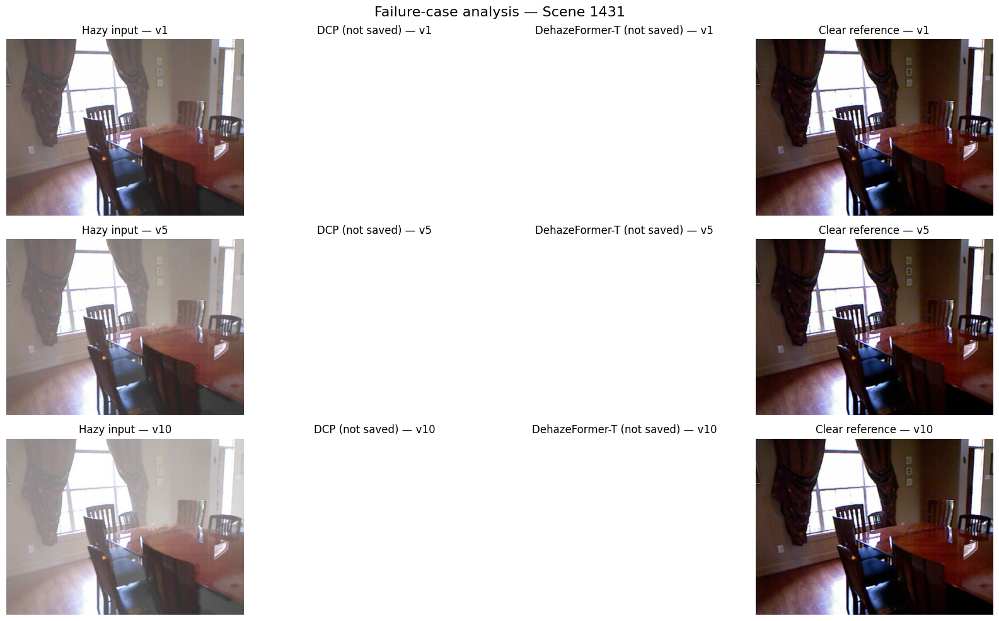

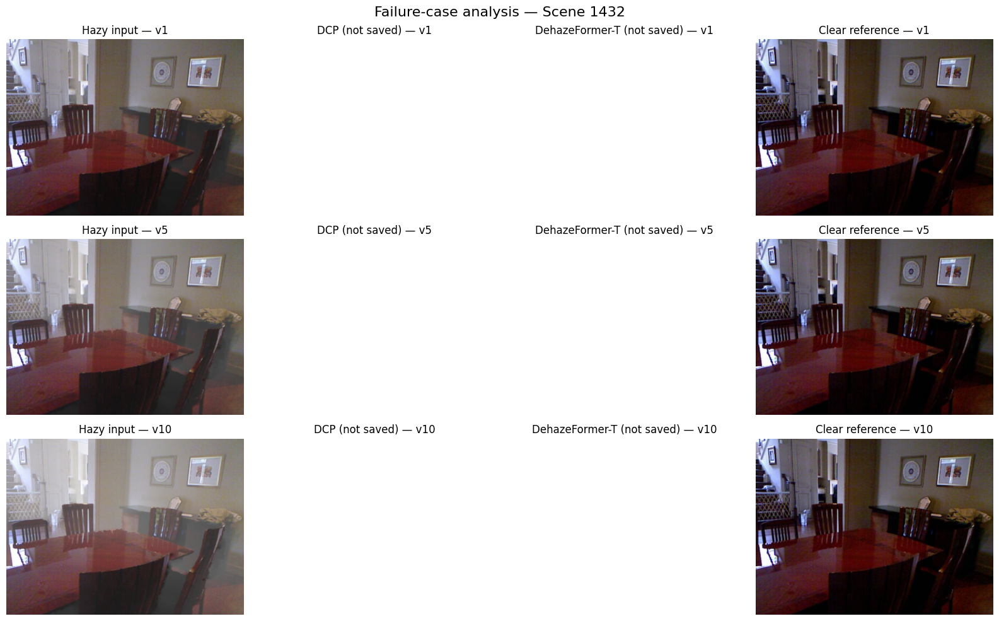

In [67]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"
hazy_dir = os.path.join(base, "hazy")
clear_dir = os.path.join(base, "clear")
results_dir = "/content/dcp_vs_dehazeformer"

df = pd.read_csv(
    os.path.join(results_dir, "per_image_results.csv")
)

# Inspect the two most difficult scenes
scenes = ["1431", "1432"]
versions = [1, 5, 10]

for scene in scenes:
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    fig.suptitle(f"Failure-case analysis — Scene {scene}", fontsize=16)

    for row, version in enumerate(versions):
        hazy_name = f"{scene}_{version}.png"
        clear_name = f"{scene}.png"

        # Hazy input and clear reference
        hazy = Image.open(
            os.path.join(hazy_dir, hazy_name)
        ).convert("RGB")

        clear = Image.open(
            os.path.join(clear_dir, clear_name)
        ).convert("RGB")

        # Previously saved DCP and DehazeFormer comparison
        match = df[df["hazy_image"] == hazy_name]
        if match.empty:
            print("Missing results for:", hazy_name)
            continue

        # The comparison images saved earlier contain:
        # Hazy | DCP | DehazeFormer-T | Clear
        # We'll locate the saved comparison by its row in the CSV.
        idx = match.index[0]
        comparison_path = os.path.join(
            results_dir, f"comparison_{idx + 1:02d}.png"
        )

        if os.path.exists(comparison_path):
            comparison = Image.open(comparison_path).convert("RGB")
            w, h = comparison.size
            panels = [
                comparison.crop((i * w // 4, 0, (i + 1) * w // 4, h))
                for i in range(4)
            ]
            titles = ["Hazy input", "DCP", "DehazeFormer-T", "Clear reference"]
        else:
            panels = [hazy, None, None, clear]
            titles = ["Hazy input", "DCP (not saved)", "DehazeFormer-T (not saved)", "Clear reference"]

        for col, (panel, title) in enumerate(zip(panels, titles)):
            axes[row, col].set_title(f"{title} — v{version}")
            if panel is not None:
                axes[row, col].imshow(panel)
            axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()

In [68]:
import os

base = "/content/drive/MyDrive/Dehazing_Project/rise"

print("=== Dataset files ===")

for root, dirs, files in os.walk(base):
    # Avoid listing every image
    dirs[:] = [d for d in dirs if d.lower() not in ["hazy", "clear"]]

    for filename in files:
        if (
            filename.lower().endswith(
                (".txt", ".md", ".json", ".yaml", ".yml", ".csv")
            )
        ):
            path = os.path.join(root, filename)
            print(path)

print("\n=== Dataset folders ===")
for folder in [
    base,
    os.path.join(base, "indoor"),
    os.path.join(base, "indoor", "hazy"),
    os.path.join(base, "indoor", "clear"),
]:
    print(f"{folder}: {'EXISTS' if os.path.isdir(folder) else 'MISSING'}")

=== Dataset files ===
/content/drive/MyDrive/Dehazing_Project/rise/metadata_indoor.csv

=== Dataset folders ===
/content/drive/MyDrive/Dehazing_Project/rise: EXISTS
/content/drive/MyDrive/Dehazing_Project/rise/indoor: EXISTS
/content/drive/MyDrive/Dehazing_Project/rise/indoor/hazy: EXISTS
/content/drive/MyDrive/Dehazing_Project/rise/indoor/clear: EXISTS


In [69]:
import pandas as pd

path = "/content/drive/MyDrive/Dehazing_Project/rise/metadata_indoor.csv"

metadata = pd.read_csv(path)

print("Shape:", metadata.shape)
print("\nColumns:")
print(metadata.columns.tolist())

print("\nFirst 5 rows:")
display(metadata.head())

print("\nExample clear-image paths:")
print(metadata["clear_image_path"].head(5).to_list())

print("\nExample hazy-image paths:")
print(metadata["hazy_image_paths"].head(3).to_list())

Shape: (50, 3)

Columns:
['image_id', 'clear_image_path', 'hazy_image_paths']

First 5 rows:


,image_id,clear_image_path,hazy_image_paths
0,1400,clear/1400.png,"['hazy/1400_1.png', 'hazy/1400_2.png', 'hazy/1..."
1,1401,clear/1401.png,"['hazy/1401_1.png', 'hazy/1401_2.png', 'hazy/1..."
2,1402,clear/1402.png,"['hazy/1402_1.png', 'hazy/1402_2.png', 'hazy/1..."
3,1403,clear/1403.png,"['hazy/1403_1.png', 'hazy/1403_2.png', 'hazy/1..."
4,1404,clear/1404.png,"['hazy/1404_1.png', 'hazy/1404_2.png', 'hazy/1..."



Example clear-image paths:
['clear/1400.png', 'clear/1401.png', 'clear/1402.png', 'clear/1403.png', 'clear/1404.png']

Example hazy-image paths:
["['hazy/1400_1.png', 'hazy/1400_2.png', 'hazy/1400_3.png', 'hazy/1400_4.png', 'hazy/1400_5.png', 'hazy/1400_6.png', 'hazy/1400_7.png', 'hazy/1400_8.png', 'hazy/1400_9.png', 'hazy/1400_10.png']", "['hazy/1401_1.png', 'hazy/1401_2.png', 'hazy/1401_3.png', 'hazy/1401_4.png', 'hazy/1401_5.png', 'hazy/1401_6.png', 'hazy/1401_7.png', 'hazy/1401_8.png', 'hazy/1401_9.png', 'hazy/1401_10.png']", "['hazy/1402_1.png', 'hazy/1402_2.png', 'hazy/1402_3.png', 'hazy/1402_4.png', 'hazy/1402_5.png', 'hazy/1402_6.png', 'hazy/1402_7.png', 'hazy/1402_8.png', 'hazy/1402_9.png', 'hazy/1402_10.png']"]


Hazy shape: (460, 620, 3)
Clear shape: (460, 620, 3)
Same dimensions: True

Model output shape: (460, 620, 3)
Input range: 0.09803921729326248 1.0
Output range: 0.0 1.0
Clear range: 0.0 1.0

=== Single-image audit ===
Hazy input PSNR: 14.785 dB
DehazeFormer PSNR: 29.734 dB
Hazy input SSIM: 0.7986
DehazeFormer SSIM: 0.9645
PSNR improvement: 14.949 dB


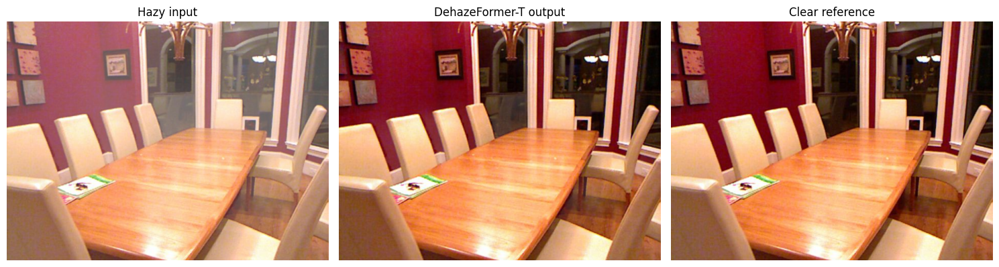

In [70]:
import os
import numpy as np
import torch
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"

hazy_path = os.path.join(base, "hazy", "1400_1.png")
clear_path = os.path.join(base, "clear", "1400.png")

# Load both images as RGB in [0, 1]
hazy = np.asarray(
    Image.open(hazy_path).convert("RGB")
).astype(np.float32) / 255.0

clear = np.asarray(
    Image.open(clear_path).convert("RGB")
).astype(np.float32) / 255.0

print("Hazy shape:", hazy.shape)
print("Clear shape:", clear.shape)
print("Same dimensions:", hazy.shape == clear.shape)

# Convert RGB [0, 1] to model input [-1, 1]
input_tensor = torch.from_numpy(hazy).permute(2, 0, 1)
input_tensor = input_tensor.unsqueeze(0).to(device)
input_tensor = input_tensor * 2.0 - 1.0

model.eval()
with torch.inference_mode():
    output_tensor = model(input_tensor).clamp(-1, 1)
    output_tensor = output_tensor * 0.5 + 0.5

output = (
    output_tensor.squeeze(0)
    .permute(1, 2, 0)
    .cpu()
    .numpy()
)
output = np.clip(output, 0, 1)

# Verify dimensions and numerical ranges
print("\nModel output shape:", output.shape)
print("Input range:", float(hazy.min()), float(hazy.max()))
print("Output range:", float(output.min()), float(output.max()))
print("Clear range:", float(clear.min()), float(clear.max()))

# Calculate metrics with identical conventions
input_psnr = peak_signal_noise_ratio(
    clear, hazy, data_range=1.0
)
output_psnr = peak_signal_noise_ratio(
    clear, output, data_range=1.0
)

input_ssim = structural_similarity(
    clear, hazy, data_range=1.0, channel_axis=2
)
output_ssim = structural_similarity(
    clear, output, data_range=1.0, channel_axis=2
)

print("\n=== Single-image audit ===")
print(f"Hazy input PSNR: {input_psnr:.3f} dB")
print(f"DehazeFormer PSNR: {output_psnr:.3f} dB")
print(f"Hazy input SSIM: {input_ssim:.4f}")
print(f"DehazeFormer SSIM: {output_ssim:.4f}")
print(f"PSNR improvement: {output_psnr - input_psnr:.3f} dB")

# Display the images
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in zip(
    axes,
    [hazy, output, clear],
    ["Hazy input", "DehazeFormer-T output", "Clear reference"]
):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [71]:
import os
import torch

checkpoint_path = "/content/DehazeFormer/dehazeformer-t.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Checkpoint size (MB):", round(os.path.getsize(checkpoint_path) / (1024**2), 3))

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", list(checkpoint.keys()))

if "epoch" in checkpoint:
    print("Epoch:", checkpoint["epoch"])

if "args" in checkpoint:
    print("Training arguments:", checkpoint["args"])

if "config" in checkpoint:
    print("Config:", checkpoint["config"])

if "state_dict" in checkpoint:
    weights = checkpoint["state_dict"]
    print("Number of weight tensors:", len(weights))
    print("First 10 weight names:")
    for name in list(weights.keys())[:10]:
        print(" ", name)

Checkpoint exists: True
Checkpoint size (MB): 2.904
Checkpoint keys: ['state_dict']
Number of weight tensors: 258
First 10 weight names:
  module.patch_embed.proj.weight
  module.patch_embed.proj.bias
  module.layer1.blocks.0.attn.conv.weight
  module.layer1.blocks.0.attn.conv.bias
  module.layer1.blocks.0.attn.V.weight
  module.layer1.blocks.0.attn.V.bias
  module.layer1.blocks.0.attn.proj.weight
  module.layer1.blocks.0.attn.proj.bias
  module.layer1.blocks.0.mlp.mlp.0.weight
  module.layer1.blocks.0.mlp.mlp.0.bias


In [72]:
import hashlib
import os

checkpoint_path = "/content/DehazeFormer/dehazeformer-t.pth"

sha256 = hashlib.sha256()

with open(checkpoint_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

print("Checkpoint:", checkpoint_path)
print("Size (bytes):", os.path.getsize(checkpoint_path))
print("SHA-256:", sha256.hexdigest())

Checkpoint: /content/DehazeFormer/dehazeformer-t.pth
Size (bytes): 3045053
SHA-256: 156497e21bbfd3bf408067b2734db1427f2a5722f3a39924ccbfaabaa59ab0da


In [73]:
%cd /content/DehazeFormer

!git remote -v
!find . -maxdepth 4 -type f -name "*.pth"

/content/DehazeFormer
origin	https://github.com/IDKiro/DehazeFormer.git (fetch)
origin	https://github.com/IDKiro/DehazeFormer.git (push)
./dehazeformer-t.pth


In [74]:
%cd /content/DehazeFormer

!grep -n -i -E "pretrain|checkpoint|saved_models|download|indoor|outdoor" README.md

/content/DehazeFormer
16:Specifically, on the most frequently used SOTS indoor set, our small model outperforms FFA-Net with only 25\% \#Param and 5\% computational cost.
17:To the best of our knowledge, our large model is the first method with the PSNR over 40 dB on the SOTS indoor set, dramatically outperforming the previous state-of-the-art methods.
48:### Download
50:You can download the pretrained models and datasets on [GoogleDrive](https://drive.google.com/drive/folders/1Yy_GH6_bydYPU6_JJzFQwig4LTh86VI4?usp=sharing) or [BaiduPan](https://pan.baidu.com/s/1WVdNccqDMnJ5k5Q__Y2dsg?pwd=gtuw) (gtuw).
58:│   ├─ indoor
90:python train.py --model dehazeformer-b --dataset RESIDE-IN --exp indoor
103:For example, we test the DehazeFormer-B on the SOTS indoor set:
106:python test.py --model dehazeformer-b --dataset RESIDE-IN --exp indoor


In [75]:
import os
import pandas as pd

results_dir = "/content/dcp_vs_dehazeformer"

for filename in ["summary_comparison.csv", "per_image_results.csv"]:
    path = os.path.join(results_dir, filename)

    print(f"\n--- {filename} ---")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        display(df.head(10))

        if filename == "summary_comparison.csv":
            print("\nFull summary:")
            display(df)
    else:
        print("File not found:", path)


--- summary_comparison.csv ---
Shape: (2, 4)


,Method,Mean PSNR (dB) ↑,Mean SSIM ↑,Mean runtime (s/image) ↓
0,Dark Channel Prior (DCP),17.944726,0.777316,0.035979
1,DehazeFormer-T,23.143056,0.920358,0.097998



Full summary:


,Method,Mean PSNR (dB) ↑,Mean SSIM ↑,Mean runtime (s/image) ↓
0,Dark Channel Prior (DCP),17.944726,0.777316,0.035979
1,DehazeFormer-T,23.143056,0.920358,0.097998



--- per_image_results.csv ---
Shape: (500, 8)


,image_id,hazy_image,DCP_PSNR_dB,DCP_SSIM,DCP_runtime_s,DehazeFormer_PSNR_dB,DehazeFormer_SSIM,DehazeFormer_runtime_s
0,1400,1400_1.png,18.848429,0.845342,0.134373,29.733769,0.964528,0.123509
1,1400,1400_2.png,18.821437,0.839760,0.058466,28.401050,0.955669,0.103294
2,1400,1400_3.png,18.858883,0.833106,0.036432,27.168071,0.945732,0.099702
3,1400,1400_4.png,18.798245,0.827543,0.063742,26.041540,0.935361,0.124910
4,1400,1400_5.png,18.761942,0.821046,0.038984,24.994547,0.924629,0.120394
5,1400,1400_6.png,18.764817,0.814592,0.035533,23.993178,0.914662,0.105456
6,1400,1400_7.png,18.698183,0.808446,0.034074,22.970681,0.903367,0.105208
7,1400,1400_8.png,18.532207,0.799941,0.036770,22.023362,0.893326,0.100947
8,1400,1400_9.png,18.470271,0.796646,0.035278,21.146859,0.883213,0.096905
9,1400,1400_10.png,18.356392,0.790699,0.034555,20.295322,0.873146,0.101209


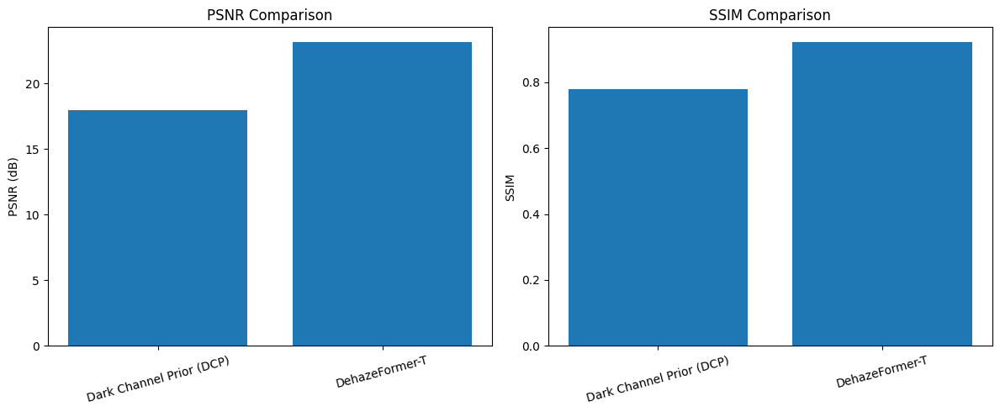

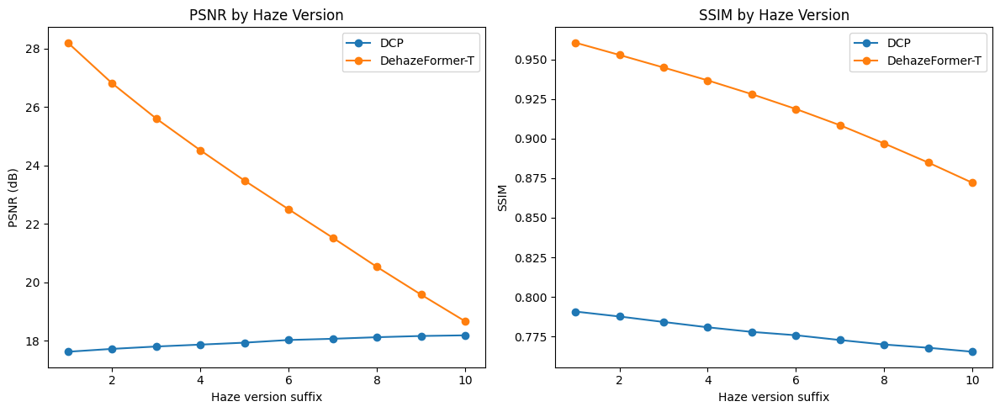

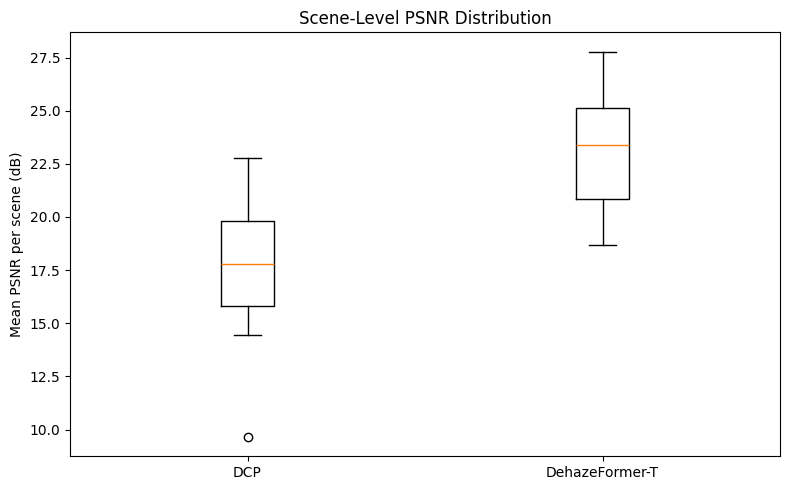

All graphs saved to: /content/dcp_vs_dehazeformer/graphs
['haze_version_analysis.png', 'scene_level_psnr.png', 'metric_comparison.png']


In [76]:

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = "/content/dcp_vs_dehazeformer"
output_folder = os.path.join(folder, "graphs")
os.makedirs(output_folder, exist_ok=True)

df = pd.read_csv(os.path.join(folder, "per_image_results.csv"))
summary = pd.read_csv(os.path.join(folder, "summary_comparison.csv"))

# Graph 1: Overall PSNR and SSIM comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(summary["Method"], summary["Mean PSNR (dB) ↑"])
axes[0].set_title("PSNR Comparison")
axes[0].set_ylabel("PSNR (dB)")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(summary["Method"], summary["Mean SSIM ↑"])
axes[1].set_title("SSIM Comparison")
axes[1].set_ylabel("SSIM")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "metric_comparison.png"), dpi=200)
plt.show()

# Graph 2: Performance across the 10 haze versions
df["version"] = df["hazy_image"].str.extract(r"_(\d+)\.png$").astype(int)

version_data = df.groupby("version").agg(
    DCP_PSNR=("DCP_PSNR_dB", "mean"),
    Model_PSNR=("DehazeFormer_PSNR_dB", "mean"),
    DCP_SSIM=("DCP_SSIM", "mean"),
    Model_SSIM=("DehazeFormer_SSIM", "mean")
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(version_data["version"], version_data["DCP_PSNR"],
             marker="o", label="DCP")
axes[0].plot(version_data["version"], version_data["Model_PSNR"],
             marker="o", label="DehazeFormer-T")
axes[0].set_title("PSNR by Haze Version")
axes[0].set_xlabel("Haze version suffix")
axes[0].set_ylabel("PSNR (dB)")
axes[0].legend()

axes[1].plot(version_data["version"], version_data["DCP_SSIM"],
             marker="o", label="DCP")
axes[1].plot(version_data["version"], version_data["Model_SSIM"],
             marker="o", label="DehazeFormer-T")
axes[1].set_title("SSIM by Haze Version")
axes[1].set_xlabel("Haze version suffix")
axes[1].set_ylabel("SSIM")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "haze_version_analysis.png"), dpi=200)
plt.show()

# Graph 3: PSNR distribution across 50 clear scenes
df["scene_id"] = df["hazy_image"].str.rsplit("_", n=1).str[0]

scene_data = df.groupby("scene_id").agg(
    DCP_PSNR=("DCP_PSNR_dB", "mean"),
    Model_PSNR=("DehazeFormer_PSNR_dB", "mean")
).reset_index()

plt.figure(figsize=(8, 5))
plt.boxplot(
    [scene_data["DCP_PSNR"], scene_data["Model_PSNR"]],
    tick_labels=["DCP", "DehazeFormer-T"]
)
plt.title("Scene-Level PSNR Distribution")
plt.ylabel("Mean PSNR per scene (dB)")
plt.tight_layout()
plt.savefig(os.path.join(output_folder, "scene_level_psnr.png"), dpi=200)
plt.show()

print("All graphs saved to:", output_folder)
print(os.listdir(output_folder))


In [78]:

from google.colab import files
import os

folder = "/content/dcp_vs_dehazeformer/graphs"

files.download(os.path.join(folder, "metric_comparison.png"))
files.download(os.path.join(folder, "haze_version_analysis.png"))
files.download(os.path.join(folder, "scene_level_psnr.png"))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [79]:

from google.colab import files
import os

# Results folder
results_folder = "/content/dcp_vs_dehazeformer"

# Download the CSV files
csv_files = [
    "summary_comparison.csv",
    "per_image_results.csv"
]

for filename in csv_files:
    path = os.path.join(results_folder, filename)
    if os.path.exists(path):
        files.download(path)
        print("Downloading:", filename)
    else:
        print("Not found:", path)

# Download all graphs
graphs_folder = os.path.join(results_folder, "graphs")

if os.path.isdir(graphs_folder):
    for filename in os.listdir(graphs_folder):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            files.download(os.path.join(graphs_folder, filename))
            print("Downloading:", filename)

# Download saved comparison images
for filename in os.listdir(results_folder):
    if filename.startswith("comparison_") and filename.lower().endswith(
        (".png", ".jpg", ".jpeg")
    ):
        files.download(os.path.join(results_folder, filename))
        print("Downloading:", filename)

print("Finished sending available result files for download.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: summary_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloading: comparison_04.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: comparison_01.png
Finished sending available result files for download.
